<a href="https://colab.research.google.com/github/Devaji-Rashmika/Deep_Learning/blob/main/skill6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Libraries imported successfully!

Dataset downloaded successfully!
Dataset extracted successfully!

Total images: 128
Total label files: 128

ANNOTATION VALIDATION
-------------------------------
Valid annotations: 899
Invalid annotations: 42
Images without label files: 2
Empty annotation files: 0
Extra label files: 2

CLASS DISTRIBUTION
person : 244
bicycle : 6
car : 47
motorcycle : 6
airplane : 6
bus : 7
train : 3
truck : 11
boat : 5
traffic light : 14
stop sign : 2
bench : 8
bird : 16
cat : 4
dog : 9
horse : 2
elephant : 16
bear : 1
zebra : 3
giraffe : 8
backpack : 6
umbrella : 17
handbag : 20
tie : 7
suitcase : 4
frisbee : 5
skis : 1
snowboard : 7
sports ball : 6
kite : 10
baseball bat : 4
baseball glove : 7
skateboard : 5
tennis racket : 7
bottle : 18
wine glass : 16
cup : 32
fork : 5
knife : 16
spoon : 22
bowl : 27
banana : 1
sandwich : 1
orange : 4
broccoli : 11
carrot : 24
hot dog : 2
pizza : 5
donut : 14
cake : 4
chair : 33
couch : 5
potted plant : 13
bed : 1
dining table : 11

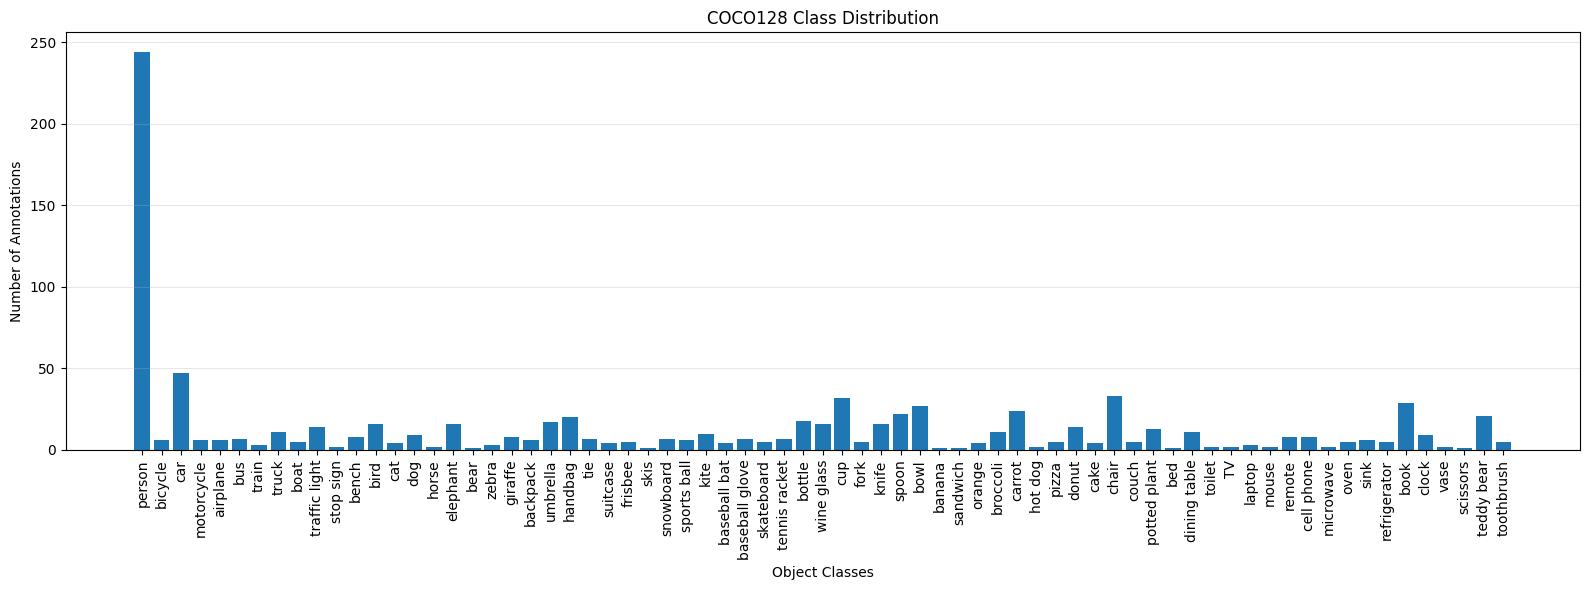


Checking image quality...

IMAGE QUALITY REPORT


,Image,Width,Height,Resolution,Brightness,Sharpness,Format
0,000000000009.jpg,640,480,307200,119.11,1722.04,.jpg
1,000000000025.jpg,640,426,272640,101.42,5758.15,.jpg
2,000000000030.jpg,640,428,273920,131.11,613.18,.jpg
3,000000000034.jpg,640,425,272000,107.23,9392.40,.jpg
4,000000000036.jpg,481,640,307840,142.32,2932.84,.jpg
5,000000000042.jpg,640,478,305920,119.65,523.31,.jpg
6,000000000049.jpg,381,500,190500,141.61,4662.29,.jpg
7,000000000061.jpg,640,488,312320,143.53,17860.79,.jpg
8,000000000064.jpg,480,640,307200,121.16,2193.46,.jpg
9,000000000071.jpg,640,426,272640,109.00,2841.52,.jpg


Readable images: 128
Corrupted images: 0


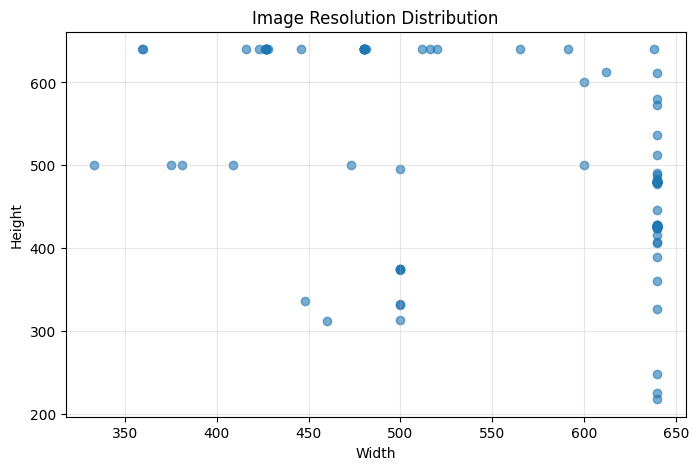

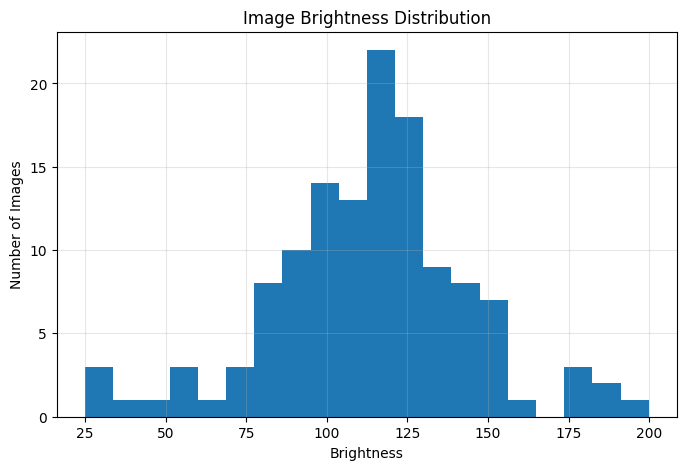

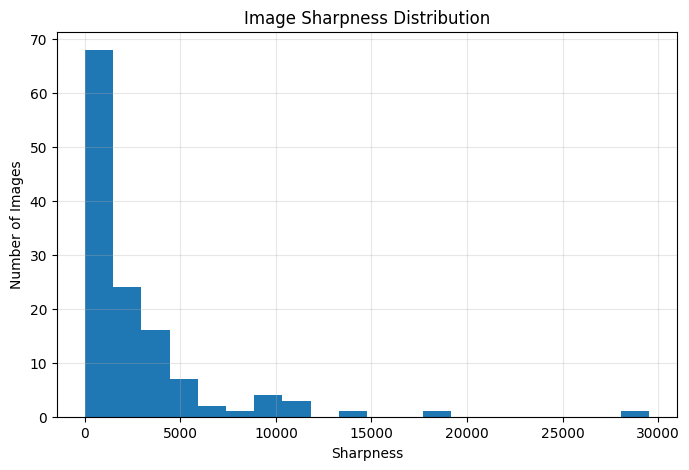

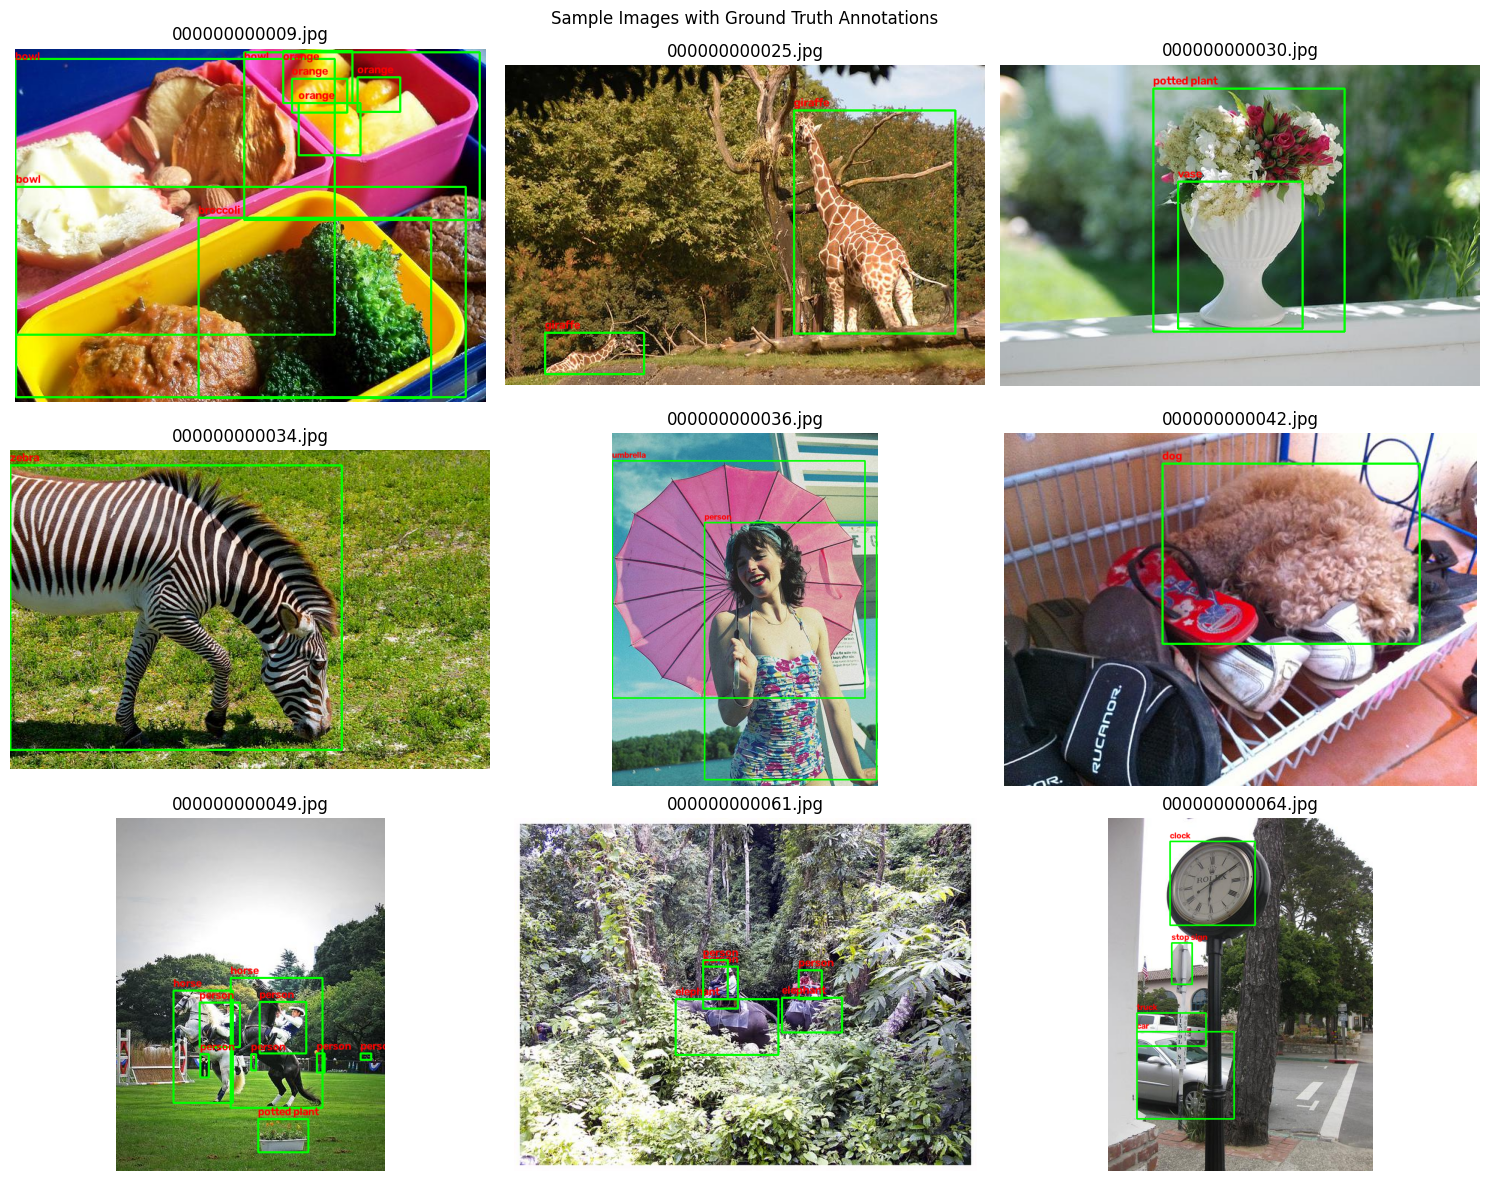


ANNOTATION DETAILS


,Class ID,Class Name,Image,X Center,Y Center,Width,Height
0,45,bowl,000000000009,0.479492,0.688771,0.955609,0.595500
1,45,bowl,000000000009,0.736516,0.247188,0.498875,0.476417
2,50,broccoli,000000000009,0.637063,0.732938,0.494125,0.510583
3,45,bowl,000000000009,0.339438,0.418896,0.678875,0.781500
4,49,orange,000000000009,0.646836,0.132552,0.118047,0.096937
5,49,orange,000000000009,0.773148,0.129802,0.090734,0.097229
6,49,orange,000000000009,0.668297,0.226906,0.131281,0.146896
7,49,orange,000000000009,0.642859,0.079219,0.148063,0.148062
8,23,giraffe,000000000025,0.770336,0.489695,0.335891,0.697559
9,23,giraffe,000000000025,0.185977,0.901608,0.206297,0.129554



       FINAL DATASET AUDIT REPORT


,Metric,Result
0,Dataset Name,COCO128
1,Total Images,128
2,Readable Images,128
3,Corrupted Images,0
4,Number of Classes Present,71
5,Valid Annotations,899
6,Invalid Annotations,42
7,Missing Annotation Files,2
8,Empty Annotation Files,0
9,Extra Label Files,2



All reports saved successfully!


<IPython.core.display.Javascript object>

... (2 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


EXPERIMENT COMPLETED SUCCESSFULLY!


In [ ]:

# ================================================================
# EXPERIMENT: DATASET AUDIT AND VISUALISATION
# Class Distribution, Image Quality and Annotation Validation
# Dataset: COCO128 (public COCO sample dataset)
# ================================================================

# 1. IMPORT LIBRARIES

import os
import zipfile
import requests
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from collections import Counter
from IPython.display import display

print("Libraries imported successfully!")

# 2. DOWNLOAD PUBLIC DATASET AUTOMATICALLY

DATASET_URL = "https://ultralytics.com/assets/coco128.zip"
ZIP_PATH = "/content/coco128.zip"
DATASET_PATH = "/content/coco128"

print("\nDownloading COCO128 dataset...")

response = requests.get(DATASET_URL, timeout=180)
response.raise_for_status()

with open(ZIP_PATH, "wb") as f:
    f.write(response.content)

print("Dataset downloaded successfully!")

# 3. EXTRACT DATASET

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall("/content/")

print("Dataset extracted successfully!")

IMAGE_DIR = Path(DATASET_PATH) / "images" / "train2017"
LABEL_DIR = Path(DATASET_PATH) / "labels" / "train2017"

if not IMAGE_DIR.exists() or not LABEL_DIR.exists():
    raise FileNotFoundError("Dataset folders were not found.")

image_extensions = {".jpg", ".jpeg", ".png"}

image_files = sorted([
    p for p in IMAGE_DIR.iterdir()
    if p.suffix.lower() in image_extensions
])

label_files = sorted(LABEL_DIR.glob("*.txt"))

print("\nTotal images:", len(image_files))
print("Total label files:", len(label_files))

# 4. COCO CLASS NAMES

class_names = [
    "person", "bicycle", "car", "motorcycle", "airplane",
    "bus", "train", "truck", "boat", "traffic light",
    "fire hydrant", "stop sign", "parking meter", "bench",
    "bird", "cat", "dog", "horse", "sheep", "cow",
    "elephant", "bear", "zebra", "giraffe", "backpack",
    "umbrella", "handbag", "tie", "suitcase", "frisbee",
    "skis", "snowboard", "sports ball", "kite", "baseball bat",
    "baseball glove", "skateboard", "surfboard", "tennis racket",
    "bottle", "wine glass", "cup", "fork", "knife", "spoon",
    "bowl", "banana", "apple", "sandwich", "orange", "broccoli",
    "carrot", "hot dog", "pizza", "donut", "cake", "chair",
    "couch", "potted plant", "bed", "dining table", "toilet",
    "TV", "laptop", "mouse", "remote", "keyboard", "cell phone",
    "microwave", "oven", "toaster", "sink", "refrigerator",
    "book", "clock", "vase", "scissors", "teddy bear",
    "hair drier", "toothbrush"
]

# 5. CLASS DISTRIBUTION AND ANNOTATION VALIDATION

class_counts = Counter()
valid_annotations = 0
invalid_annotations = 0
missing_annotations = 0
empty_annotations = 0

annotation_details = []

image_stems = {p.stem for p in image_files}
label_stems = {p.stem for p in label_files}

missing_labels = image_stems - label_stems
extra_labels = label_stems - image_stems

missing_annotations = len(missing_labels)

for label_file in label_files:

    lines = label_file.read_text().splitlines()

    if not lines:
        empty_annotations += 1

    for line in lines:

        parts = line.strip().split()

        if len(parts) != 5:
            invalid_annotations += 1
            continue

        try:
            cls = int(parts[0])
            x, y, w, h = map(float, parts[1:])

            if (
                cls < 0 or cls >= len(class_names)
                or not np.all(np.isfinite([x, y, w, h]))
                or not (0 <= x <= 1)
                or not (0 <= y <= 1)
                or not (0 < w <= 1)
                or not (0 < h <= 1)
                or x - w / 2 < 0
                or y - h / 2 < 0
                or x + w / 2 > 1
                or y + h / 2 > 1
            ):
                invalid_annotations += 1
                continue

            valid_annotations += 1
            class_counts[cls] += 1

            annotation_details.append({
                "Class ID": cls,
                "Class Name": class_names[cls],
                "Image": label_file.stem,
                "X Center": x,
                "Y Center": y,
                "Width": w,
                "Height": h
            })

        except (ValueError, OverflowError):
            invalid_annotations += 1

print("\nANNOTATION VALIDATION")
print("-------------------------------")
print("Valid annotations:", valid_annotations)
print("Invalid annotations:", invalid_annotations)
print("Images without label files:", missing_annotations)
print("Empty annotation files:", empty_annotations)
print("Extra label files:", len(extra_labels))

# 6. CLASS DISTRIBUTION GRAPH

print("\nCLASS DISTRIBUTION")

if class_counts:

    distribution = {
        class_names[k]: v
        for k, v in sorted(class_counts.items())
    }

    for name, count in distribution.items():
        print(name, ":", count)

    plt.figure(figsize=(16, 6))
    plt.bar(distribution.keys(), distribution.values())

    plt.title("COCO128 Class Distribution")
    plt.xlabel("Object Classes")
    plt.ylabel("Number of Annotations")
    plt.xticks(rotation=90)
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

# 7. IMAGE QUALITY ANALYSIS

image_quality = []
corrupted_images = []

print("\nChecking image quality...")

for image_path in image_files:

    img = cv2.imread(str(image_path))

    if img is None:
        corrupted_images.append(image_path.name)
        continue

    height, width = img.shape[:2]

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    brightness = float(np.mean(gray))

    sharpness = float(
        cv2.Laplacian(gray, cv2.CV_64F).var()
    )

    image_quality.append({
        "Image": image_path.name,
        "Width": width,
        "Height": height,
        "Resolution": width * height,
        "Brightness": round(brightness, 2),
        "Sharpness": round(sharpness, 2),
        "Format": image_path.suffix
    })

image_df = pd.DataFrame(image_quality)

print("\nIMAGE QUALITY REPORT")
display(image_df.head(10))

print("Readable images:", len(image_df))
print("Corrupted images:", len(corrupted_images))

# 8. IMAGE RESOLUTION DISTRIBUTION

plt.figure(figsize=(8, 5))

plt.scatter(
    image_df["Width"],
    image_df["Height"],
    alpha=0.6
)

plt.title("Image Resolution Distribution")
plt.xlabel("Width")
plt.ylabel("Height")
plt.grid(alpha=0.3)
plt.show()

# 9. IMAGE BRIGHTNESS DISTRIBUTION

plt.figure(figsize=(8, 5))

plt.hist(image_df["Brightness"], bins=20)

plt.title("Image Brightness Distribution")
plt.xlabel("Brightness")
plt.ylabel("Number of Images")
plt.grid(alpha=0.3)
plt.show()

# 10. IMAGE SHARPNESS DISTRIBUTION

plt.figure(figsize=(8, 5))

plt.hist(image_df["Sharpness"], bins=20)

plt.title("Image Sharpness Distribution")
plt.xlabel("Sharpness")
plt.ylabel("Number of Images")
plt.grid(alpha=0.3)
plt.show()

# 11. VISUALISE SAMPLE IMAGES WITH BOUNDING BOXES

sample_images = image_files[:9]

plt.figure(figsize=(15, 12))

for i, image_path in enumerate(sample_images):

    img = cv2.imread(str(image_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    h, w = img.shape[:2]

    label_path = LABEL_DIR / (image_path.stem + ".txt")

    if label_path.exists():

        for line in label_path.read_text().splitlines():

            parts = line.split()

            if len(parts) != 5:
                continue

            try:
                cls, xc, yc, bw, bh = int(parts[0]), *map(float, parts[1:])

                if not (0 <= cls < len(class_names)):
                    continue

                x1 = int((xc - bw / 2) * w)
                y1 = int((yc - bh / 2) * h)
                x2 = int((xc + bw / 2) * w)
                y2 = int((yc + bh / 2) * h)

                cv2.rectangle(
                    img, (x1, y1), (x2, y2),
                    (0, 255, 0), 2
                )

                cv2.putText(
                    img,
                    class_names[cls],
                    (x1, max(y1 - 5, 15)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.5,
                    (255, 0, 0),
                    2
                )

            except (ValueError, IndexError):
                continue

    plt.subplot(3, 3, i + 1)
    plt.imshow(img)
    plt.title(image_path.name)
    plt.axis("off")

plt.suptitle("Sample Images with Ground Truth Annotations")
plt.tight_layout()
plt.show()

# 12. ANNOTATION DETAILS TABLE

annotation_df = pd.DataFrame(annotation_details)

print("\nANNOTATION DETAILS")
display(annotation_df.head(10))

# 13. FINAL DATASET AUDIT SUMMARY

summary = pd.DataFrame({
    "Metric": [
        "Dataset Name",
        "Total Images",
        "Readable Images",
        "Corrupted Images",
        "Number of Classes Present",
        "Valid Annotations",
        "Invalid Annotations",
        "Missing Annotation Files",
        "Empty Annotation Files",
        "Extra Label Files"
    ],

    "Result": [
        "COCO128",
        len(image_files),
        len(image_df),
        len(corrupted_images),
        len(class_counts),
        valid_annotations,
        invalid_annotations,
        missing_annotations,
        empty_annotations,
        len(extra_labels)
    ]
})

print("\n======================================")
print("       FINAL DATASET AUDIT REPORT")
print("======================================")

display(summary)

# 14. SAVE REPORTS AS CSV FILES

image_df.to_csv(
    "/content/image_quality_report.csv",
    index=False
)

summary.to_csv(
    "/content/dataset_audit_summary.csv",
    index=False
)

annotation_df.to_csv(
    "/content/annotation_validation_report.csv",
    index=False
)

print("\nAll reports saved successfully!")

# 15. DOWNLOAD REPORTS

from google.colab import files

files.download("/content/image_quality_report.csv")
files.download("/content/dataset_audit_summary.csv")
files.download("/content/annotation_validation_report.csv")

print("\nEXPERIMENT COMPLETED SUCCESSFULLY!")
